# Phase 12 — Model Validation & Robustness Checks

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Audit the Phase 11 Random Forest result before making stronger claims. This phase checks target construction, predictor leakage, time-split integrity, performance against a training-mean baseline, prediction bias, and performance across time and tickers.

**Important:** This phase is an audit. It does not automatically certify the model as reliable, profitable, or suitable for investment decisions.

## 1. Setup and locate project files

Run cells from top to bottom. The notebook searches for the Phase 10 feature table and Phase 11 output files.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

FEATURE_REL = Path("data/processed/model_features/asx_3m_return_features_and_targets.csv")
PRED_REL = Path("data/processed/model_predictions/asx_3m_return_test_predictions.csv")
SUMMARY_REL = Path("reports/model_training/phase11_run_summary.json")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / FEATURE_REL).exists():
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and (p / FEATURE_REL).exists():
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Cannot find {FEATURE_REL}. Set PROJECT_ROOT manually.")
FEATURE_PATH = PROJECT_ROOT / FEATURE_REL
PRED_PATH = PROJECT_ROOT / PRED_REL
SUMMARY_PATH = PROJECT_ROOT / SUMMARY_REL
OUT = PROJECT_ROOT / "reports" / "model_validation"
OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Feature file exists:", FEATURE_PATH.exists())
print("Prediction file exists:", PRED_PATH.exists())
print("Phase 11 summary exists:", SUMMARY_PATH.exists())

Project root: e:\Projects\Australian Stock Market Data Science Project
Feature file exists: True
Prediction file exists: True
Phase 11 summary exists: True


## 2. Load and inspect Phase 11 artifacts

In [2]:
features = pd.read_csv(FEATURE_PATH, low_memory=False)
features["ticker"] = features["ticker"].astype(str).str.strip().str.upper()
features["date"] = pd.to_datetime(features["date"], errors="coerce")
features["forward_return_3m"] = pd.to_numeric(features["forward_return_3m"], errors="coerce")

predictions = None
if PRED_PATH.exists():
    predictions = pd.read_csv(PRED_PATH, low_memory=False)
    predictions["ticker"] = predictions["ticker"].astype(str).str.strip().str.upper()
    predictions["date"] = pd.to_datetime(predictions["date"], errors="coerce")
    for col in ["forward_return_3m", "predicted_forward_return_3m", "prediction_error"]:
        if col in predictions.columns:
            predictions[col] = pd.to_numeric(predictions[col], errors="coerce")

phase11_summary = {}
if SUMMARY_PATH.exists():
    with open(SUMMARY_PATH, "r", encoding="utf-8") as f:
        phase11_summary = json.load(f)

print("Feature table shape:", features.shape)
print("Tickers:", features["ticker"].nunique())
print("Dates:", features["date"].min(), "to", features["date"].max())
print("Non-null target rows:", features["forward_return_3m"].notna().sum())
if predictions is not None:
    print("Prediction table shape:", predictions.shape)
    display(predictions.head())
display(features[["ticker", "date", "forward_return_3m"]].head())

Feature table shape: (62495, 47)
Tickers: 52
Dates: 2021-10-19 00:00:00 to 2026-07-22 00:00:00
Non-null target rows: 62495
Prediction table shape: (9412, 5)


,ticker,date,forward_return_3m,predicted_forward_return_3m,prediction_error
0,A2M,2025-11-03,-0.110187,-0.083704,-0.026483
1,ACL,2025-11-03,0.019011,0.052797,-0.033786
2,ADH,2025-11-03,-0.094059,-0.123113,0.029054
3,AFG,2025-11-03,-0.131356,-0.110762,-0.020594
4,ALD,2025-11-03,-0.062723,-0.023480,-0.039243


,ticker,date,forward_return_3m
0,A2M,2021-10-19,-0.229555
1,ACL,2021-10-19,0.278802
2,ADH,2021-10-19,-0.005102
3,AFG,2021-10-19,-0.066176
4,ALD,2021-10-19,0.010383


## 3. Recalculate prediction metrics and compare with the training-mean baseline

The baseline must use only the training + validation target mean. We read that value from the Phase 11 feature data and the chronological cutoffs if available. The code below reconstructs the same chronological split logic and 63-date purge used in Phase 11.

In [3]:
if predictions is None:
    raise FileNotFoundError(
        f"Missing {PRED_PATH}. Run Phase 11 through the prediction export cell first."
    )

PURGE_OBSERVATIONS = 63
target_df = features.dropna(subset=["ticker", "date", "forward_return_3m"]).copy()
dates = np.array(sorted(target_df["date"].dropna().unique()))
if len(dates) < 20:
    raise ValueError("Too few target dates to reconstruct the Phase 11 split.")

train_cut_idx = max(1, int(len(dates) * 0.70) - 1)
valid_cut_idx = max(train_cut_idx + 1, int(len(dates) * 0.85) - 1)
train_cut_date = pd.Timestamp(dates[train_cut_idx])
valid_cut_date = pd.Timestamp(dates[valid_cut_idx])

train_dates = dates[dates <= train_cut_date]
valid_dates = dates[(dates > train_cut_date) & (dates <= valid_cut_date)]
test_dates = dates[dates > valid_cut_date]
purged_train_dates = train_dates[:-PURGE_OBSERVATIONS]
purged_valid_dates = valid_dates[:-PURGE_OBSERVATIONS] if len(valid_dates) > PURGE_OBSERVATIONS else np.array([], dtype="datetime64[ns]")

train = target_df[target_df["date"].isin(purged_train_dates)].copy()
valid = target_df[target_df["date"].isin(purged_valid_dates)].copy()
train_valid = pd.concat([train, valid], ignore_index=True)
y_train_valid = train_valid["forward_return_3m"].astype(float)

test = predictions.dropna(subset=["forward_return_3m", "predicted_forward_return_3m"]).copy()
actual = test["forward_return_3m"].astype(float).to_numpy()
pred = test["predicted_forward_return_3m"].astype(float).to_numpy()
baseline_pred = np.full(len(test), float(y_train_valid.mean()))

def metric_row(name, y, p):
    return {
        "model": name,
        "n": int(len(y)),
        "MAE": float(mean_absolute_error(y, p)),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "R2": float(r2_score(y, p)) if len(y) >= 2 else np.nan,
        "actual_mean": float(np.mean(y)),
        "predicted_mean": float(np.mean(p)),
        "prediction_bias_mean_pred_minus_actual": float(np.mean(p) - np.mean(y))
    }

recalculated_metrics = pd.DataFrame([
    metric_row("Training+validation mean baseline", actual, baseline_pred),
    metric_row("Phase 11 selected model", actual, pred)
])
display(recalculated_metrics)
recalculated_metrics.to_csv(OUT / "recalculated_test_metrics.csv", index=False)

print("Training+validation target mean:", round(float(y_train_valid.mean()), 6))
print("Test target mean:", round(float(np.mean(actual)), 6))
print("Test prediction mean:", round(float(np.mean(pred)), 6))

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,prediction_bias_mean_pred_minus_actual
0,Training+validation mean baseline,9412,0.143784,0.184964,-0.044950,-0.009888,0.028474,0.038362
1,Phase 11 selected model,9412,0.091714,0.124164,0.529122,-0.009888,0.030212,0.040100


Training+validation target mean: 0.028474
Test target mean: -0.009888
Test prediction mean: 0.030212


## 4. Check prediction bias and distribution

A substantial difference between the mean actual return and mean predicted return can indicate calibration bias, a distribution shift, or an unstable model. This is not necessarily leakage, but it needs to be reported.

,quantity,value
0,Actual test mean,-0.009888
1,Predicted test mean,0.030212
2,Mean prediction minus actual,0.040100
3,Actual test median,-0.009421
4,Predicted test median,-0.000932
5,Actual test standard deviation,0.180952
6,Predicted test standard deviation,0.126125


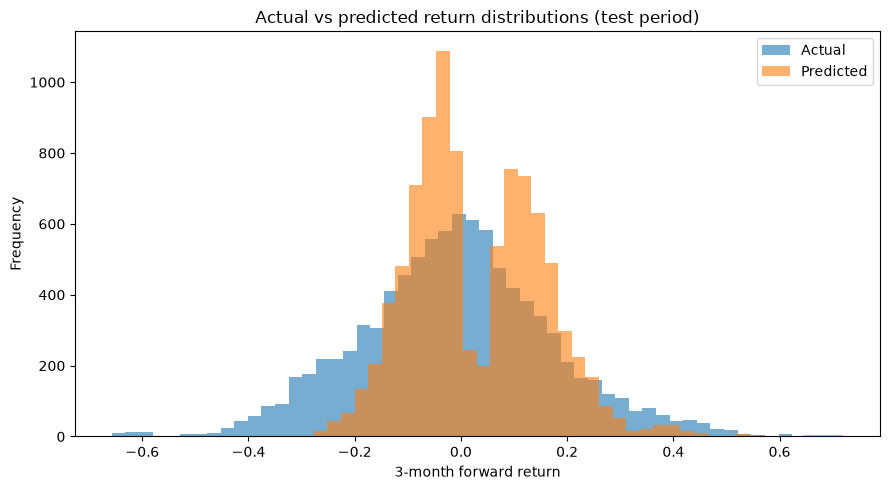

In [4]:
bias_summary = pd.DataFrame([
    {"quantity": "Actual test mean", "value": float(np.mean(actual))},
    {"quantity": "Predicted test mean", "value": float(np.mean(pred))},
    {"quantity": "Mean prediction minus actual", "value": float(np.mean(pred) - np.mean(actual))},
    {"quantity": "Actual test median", "value": float(np.median(actual))},
    {"quantity": "Predicted test median", "value": float(np.median(pred))},
    {"quantity": "Actual test standard deviation", "value": float(np.std(actual, ddof=1))},
    {"quantity": "Predicted test standard deviation", "value": float(np.std(pred, ddof=1))}
])
display(bias_summary)
bias_summary.to_csv(OUT / "prediction_bias_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(actual, bins=50, alpha=0.6, label="Actual")
ax.hist(pred, bins=50, alpha=0.6, label="Predicted")
ax.set_xlabel("3-month forward return")
ax.set_ylabel("Frequency")
ax.set_title("Actual vs predicted return distributions (test period)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "actual_vs_predicted_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Verify target horizon and ticker-wise ordering

The target file does not necessarily preserve the exact future-date endpoint used for each label. If Phase 9 saved explicit endpoint columns, this cell inspects them. It also checks whether target values appear to have been generated in ticker/date order, and summarizes target coverage by ticker.

In [5]:
endpoint_cols = [c for c in features.columns if any(term in c.lower() for term in ["target_date", "future_date", "end_date", "forward_date", "horizon_date"])]
print("Possible target endpoint columns:", endpoint_cols if endpoint_cols else "None found")
display(features.groupby("ticker").agg(
    rows=("date", "size"),
    target_rows=("forward_return_3m", "count"),
    first_date=("date", "min"),
    last_date=("date", "max")
).sort_values("target_rows").head(15).reset_index())

# Coverage diagnostics: proportion of rows per ticker with a non-null 3-month label.
ticker_coverage = features.groupby("ticker").agg(
    rows=("date", "size"),
    target_rows=("forward_return_3m", "count")
).reset_index()
ticker_coverage["target_coverage_pct"] = 100 * ticker_coverage["target_rows"] / ticker_coverage["rows"].replace(0, np.nan)
ticker_coverage.to_csv(OUT / "ticker_target_coverage.csv", index=False)

Possible target endpoint columns: None found


,ticker,rows,target_rows,first_date,last_date
0,STP,1193,1193,2021-11-01,2026-07-22
1,A2M,1202,1202,2021-10-19,2026-07-22
2,ADH,1202,1202,2021-10-19,2026-07-22
3,ACL,1202,1202,2021-10-19,2026-07-22
4,ALD,1202,1202,2021-10-19,2026-07-22
5,ANN,1202,1202,2021-10-19,2026-07-22
6,ANZ,1202,1202,2021-10-19,2026-07-22
7,AFG,1202,1202,2021-10-19,2026-07-22
8,ASG,1202,1202,2021-10-19,2026-07-22
9,ASH,1202,1202,2021-10-19,2026-07-22


## 6. Audit feature names for possible leakage

This is a name-based screen, not a guarantee. Review any feature that encodes future prices, forward returns, outcomes, or target construction. Features must be available on the prediction date.

In [6]:
suspicious_terms = [
    "forward_return", "forward_outperform", "future_return", "future_price",
    "target", "label", "next_return", "next_price", "future", "lead"
]
suspicious_features = [
    c for c in features.columns
    if any(term in c.lower() for term in suspicious_terms)
]
print("Columns needing manual review:")
for c in suspicious_features:
    print(" -", c)

Columns needing manual review:
 - future_price_1m
 - forward_return_1m
 - future_price_3m
 - forward_return_3m
 - future_price_6m
 - forward_return_6m
 - benchmark_forward_return_1m
 - benchmark_forward_return_3m
 - benchmark_forward_return_6m
 - relative_forward_return_1m
 - relative_forward_return_3m
 - relative_forward_return_6m


## 7. Evaluate performance by calendar period and ticker

A strong aggregate score can hide weak performance in particular periods or companies. We report monthly aggregate metrics and ticker-level metrics when enough observations are available. These are diagnostics; ticker-level scores with few rows are noisy.

In [7]:
test["month"] = test["date"].dt.to_period("M").astype(str)
monthly_rows = []
for month, group in test.groupby("month"):
    if len(group) >= 2:
        monthly_rows.append({
            "month": month,
            "n": len(group),
            "MAE": mean_absolute_error(group["forward_return_3m"], group["predicted_forward_return_3m"]),
            "RMSE": np.sqrt(mean_squared_error(group["forward_return_3m"], group["predicted_forward_return_3m"])),
            "actual_mean": group["forward_return_3m"].mean(),
            "predicted_mean": group["predicted_forward_return_3m"].mean()
        })
monthly_metrics = pd.DataFrame(monthly_rows)
display(monthly_metrics)
monthly_metrics.to_csv(OUT / "monthly_test_metrics.csv", index=False)

ticker_rows = []
for ticker, group in test.groupby("ticker"):
    if len(group) >= 20:
        ticker_rows.append({
            "ticker": ticker,
            "n": len(group),
            "MAE": mean_absolute_error(group["forward_return_3m"], group["predicted_forward_return_3m"]),
            "RMSE": np.sqrt(mean_squared_error(group["forward_return_3m"], group["predicted_forward_return_3m"])),
            "actual_mean": group["forward_return_3m"].mean(),
            "predicted_mean": group["predicted_forward_return_3m"].mean()
        })
ticker_metrics = pd.DataFrame(ticker_rows).sort_values("MAE") if ticker_rows else pd.DataFrame()
display(ticker_metrics.head(10))
ticker_metrics.to_csv(OUT / "ticker_test_metrics.csv", index=False)

,month,n,MAE,RMSE,actual_mean,predicted_mean
0,2025-11,1040,0.076814,0.101066,-0.020787,-0.000422
1,2025-12,1092,0.086874,0.110201,-0.064218,-0.004251
2,2026-01,1040,0.093053,0.128744,-0.068537,-0.010424
3,2026-02,1040,0.105829,0.141562,-0.085552,-0.013794
4,2026-03,1144,0.093935,0.124900,-0.012372,0.019793
5,2026-04,1040,0.088856,0.119460,0.014075,0.058407
6,2026-05,1092,0.090214,0.126699,0.086130,0.097585
7,2026-06,1092,0.094179,0.129401,0.047568,0.068014
8,2026-07,832,0.096627,0.132629,0.014966,0.060586


,ticker,n,MAE,RMSE,actual_mean,predicted_mean
6,ANZ,181,0.035774,0.046175,0.024645,0.050822
16,COL,181,0.038484,0.050846,0.040112,0.068836
12,BGA,181,0.038870,0.052625,0.024609,0.034044
15,CBA,181,0.039406,0.048253,0.021650,0.019369
13,BOQ,181,0.039512,0.047459,0.017855,0.034191
48,WBC,181,0.046903,0.058188,-0.021335,0.015670
46,SVR,181,0.047492,0.064083,-0.009992,0.008742
37,QBE,181,0.051109,0.064373,0.084842,0.063427
42,SIG,181,0.051935,0.066878,-0.018654,0.000740
24,IAG,181,0.053658,0.066548,0.032087,0.073353


## 8. Recheck chronological split boundaries and overlap risk

This check makes the date split explicit. Because each label looks forward by approximately 63 ticker observations, purging by 63 **global unique dates** is conservative in some respects but may not perfectly represent each ticker's actual label endpoint. The strongest design is to save the label endpoint date during Phase 9 and purge based on endpoint dates. If such endpoints were not saved, this notebook documents the limitation rather than pretending the purge is exact.

In [8]:
boundary_report = pd.DataFrame([
    {"split": "purged train", "first_date": train["date"].min(), "last_date": train["date"].max(), "rows": len(train)},
    {"split": "purged validation", "first_date": valid["date"].min() if len(valid) else pd.NaT, "last_date": valid["date"].max() if len(valid) else pd.NaT, "rows": len(valid)},
    {"split": "held-out test", "first_date": test["date"].min(), "last_date": test["date"].max(), "rows": len(test)}
])
display(boundary_report)
boundary_report.to_csv(OUT / "split_boundary_audit.csv", index=False)

if endpoint_cols:
    print("Endpoint-like columns exist. Inspect them and use actual target endpoints for a stricter purge.")
else:
    print("No explicit target endpoint column found. The 63-date purge is an approximation, not proof of zero overlap.")

,split,first_date,last_date,rows
0,purged train,2021-10-19,2024-11-14,40447
1,purged validation,2025-02-18,2025-08-05,6084
2,held-out test,2025-11-03,2026-07-22,9412


No explicit target endpoint column found. The 63-date purge is an approximation, not proof of zero overlap.


## 9. Produce an audit summary and conclusion

This summary flags a large mean-prediction gap for manual review. The threshold is a diagnostic trigger, not a statistical significance test.

In [9]:
actual_mean = float(np.mean(actual))
pred_mean = float(np.mean(pred))
mean_gap = pred_mean - actual_mean
actual_std = float(np.std(actual, ddof=1)) if len(actual) > 1 else np.nan
gap_flag = bool(np.isfinite(actual_std) and abs(mean_gap) > 0.25 * actual_std)

summary = {
    "phase": 12,
    "target": "forward_return_3m",
    "test_rows": int(len(test)),
    "test_tickers": int(test["ticker"].nunique()),
    "n_predictors_in_phase11": phase11_summary.get("n_features"),
    "actual_test_mean": actual_mean,
    "predicted_test_mean": pred_mean,
    "prediction_mean_gap": mean_gap,
    "large_mean_gap_flag": gap_flag,
    "recalculated_metrics": recalculated_metrics.to_dict(orient="records"),
    "explicit_target_endpoint_columns_found": endpoint_cols,
    "purge_limit": "Phase 11 purged 63 global unique dates; exact label-endpoint purging requires endpoint dates saved in Phase 9.",
    "conclusion": "Review leakage, target endpoint alignment, and baseline comparison before claiming robust predictive performance."
}
with open(OUT / "phase12_validation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

print(json.dumps(summary, indent=2, default=str))
print("\nPhase 12 audit outputs saved to:", OUT)

{
  "phase": 12,
  "target": "forward_return_3m",
  "test_rows": 9412,
  "test_tickers": 52,
  "n_predictors_in_phase11": 32,
  "actual_test_mean": -0.009887806217044012,
  "predicted_test_mean": 0.030212474276559168,
  "prediction_mean_gap": 0.04010028049360318,
  "large_mean_gap_flag": false,
  "recalculated_metrics": [
    {
      "model": "Training+validation mean baseline",
      "n": 9412,
      "MAE": 0.14378448609198502,
      "RMSE": 0.18496449458380324,
      "R2": -0.04494967189046384,
      "actual_mean": -0.009887806217044012,
      "predicted_mean": 0.028474432730444876,
      "prediction_bias_mean_pred_minus_actual": 0.038362238947488886
    },
    {
      "model": "Phase 11 selected model",
      "n": 9412,
      "MAE": 0.0917140531097856,
      "RMSE": 0.12416382162328857,
      "R2": 0.5291215922881065,
      "actual_mean": -0.009887806217044012,
      "predicted_mean": 0.030212474276559168,
      "prediction_bias_mean_pred_minus_actual": 0.04010028049360318
    }
  ]

## 10. Completion checklist

Before proceeding:
- Confirm the selected model's test MAE and RMSE are better than the training+validation mean baseline.
- Inspect the feature leakage review manually.
- Review monthly metrics for periods with unusually poor results.
- Confirm whether Phase 9 stored the actual endpoint date for each 3-month target.
- If the endpoint date was not saved, consider updating Phase 9 and rerunning Phases 10–12 for a stricter leakage-safe evaluation.
- Record limitations honestly; do not claim a profitable strategy from regression metrics alone.